### Question 1 ###

In [5]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50
trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=0)
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=0)

**(a) Add a middle layer (100 nodes, sigmoid)**

In [6]:
Din, H, K = 3*32*32, 100, 10
std = 1e-2

# layer 1: input -> 100 hidden nodes
w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)
# layer 2: 100 hidden nodes -> 10 outputs
w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

def sigmoid(z):
    return 1.0 / (1.0 + torch.exp(-z))

def forward(x):
    h = sigmoid(x.mm(w1) + b1)   # middle layer with sigmoid activation
    scores = h.mm(w2) + b2       # output layer
    return h, scores

**(b) Cross entropy loss**

In [7]:
def softmax(z):
    z = z - z.max(dim=1, keepdim=True).values   # numerical stability
    e = torch.exp(z)
    return e / e.sum(dim=1, keepdim=True)

def cross_entropy(scores, y_onehot):
    N = scores.shape[0]
    p = softmax(scores)
    loss = -(1.0 / N) * torch.sum(y_onehot * torch.log(p + 1e-12))
    return loss, p

def backward(x, h, p, y_onehot):
    N = x.shape[0]
    dscores = (p - y_onehot) / N         # gradient of cross-entropy + softmax
    dw2 = h.t().mm(dscores)
    db2 = dscores.sum(dim=0)
    dh = dscores.mm(w2.t())
    dz1 = dh * h * (1 - h)               # sigmoid derivative
    dw1 = x.t().mm(dz1)
    db1 = dz1.sum(dim=0)
    return dw1, db1, dw2, db2

**(c) Run 10 epochs, report train and test accuracy**

Epoch 1/10, Loss: 1.9845
Epoch 2/10, Loss: 1.7925
Epoch 3/10, Loss: 1.7251
Epoch 4/10, Loss: 1.6836
Epoch 5/10, Loss: 1.6543
Epoch 6/10, Loss: 1.6300
Epoch 7/10, Loss: 1.6098
Epoch 8/10, Loss: 1.5918
Epoch 9/10, Loss: 1.5768
Epoch 10/10, Loss: 1.5629


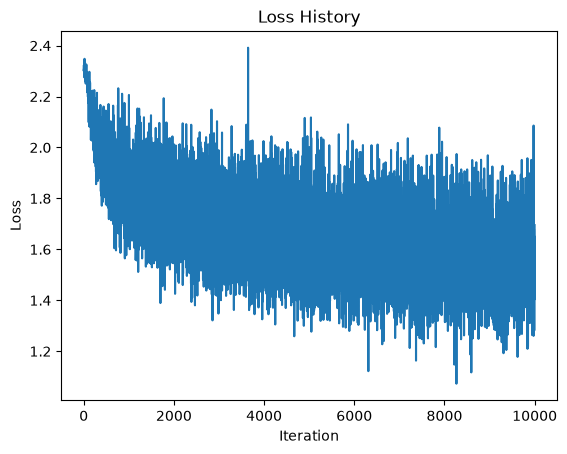

Training accuracy: 46.47%
Test accuracy: 44.91%


In [8]:
epochs = 10
lr = 5e-2
lr_decay = 0.9
loss_history = []

for t in range(epochs):
    running_loss = 0.0
    for inputs, labels in trainloader:
        N = inputs.shape[0]
        x = inputs.view(N, -1)
        y = nn.functional.one_hot(labels, K).float()

        h, scores = forward(x)
        loss, p = cross_entropy(scores, y)
        loss_history.append(loss.item())
        running_loss += loss.item()

        dw1, db1, dw2, db2 = backward(x, h, p, y)
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    print(f"Epoch {t+1}/{epochs}, Loss: {running_loss/len(trainloader):.4f}")
    lr *= lr_decay

# loss plot
plt.plot(loss_history)
plt.title("Loss History"); plt.xlabel("Iteration"); plt.ylabel("Loss")
plt.show()

# accuracy
def accuracy(loader):
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1)
            _, scores = forward(x)
            correct += (scores.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return 100 * correct / total

print(f"Training accuracy: {accuracy(trainloader):.2f}%")
print(f"Test accuracy: {accuracy(testloader):.2f}%")

**Discussion**

- Increasing the learning rate from 0.01 to 0.05 improved test accuracy from 37.08% to 44.91% and reduced the final loss from 1.79 to 1.56, indicating better learning within 10 epochs.

- The second run maintained a lower loss throughout training, starting at 1.98 compared with 2.21 in the first run. This suggests that the higher learning rate enabled faster convergence through larger parameter updates.

- The loss was still decreasing at epoch 10, suggesting that additional training might improve performance. However, further experiments are needed to determine whether more epochs or a different learning rate would be beneficial.

- The second run achieved 46.47% training accuracy and 44.91% test accuracy, a small gap of 1.56 percentage points. This indicates that there is no strong evidence of overfitting at this stage.

- The model achieved only around 45% test accuracy partly because flattening images into one-dimensional vectors loses their spatial structure. Unlike dense networks, CNNs can learn local patterns such as edges, shapes, and neighbouring pixels using local connections and shared weights, often with fewer parameters.

- Cross-entropy loss combined with softmax provides a useful gradient for classification, simplifying the output-layer gradient to \(p-y\), where \(p\) is the predicted probability vector and \(y\) is the one-hot target vector. In contrast, MSE combined with softmax can produce smaller gradients for saturated predictions, potentially slowing learning when predictions are incorrect.

### Question 2 ###